<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_affiner_bert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint: Affiner BERT pour l'analyse de sentiments (SST-2)

**Objectif** :

Affiner un modèle BERT pré-entraîné (par ex. bert-base-uncased) sur une tâche de classification de sentiments en utilisant un jeu de données étiqueté (par ex. IMDb, SST-2 ou votre propre jeu de données).

## 1. Préparer l'environnement

In [1]:
!pip install -q transformers datasets accelerate

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import (BertTokenizer, BertForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

set_seed(42)
print("GPU disponible :", torch.cuda.is_available())

GPU disponible : True


## 2. Charger le tokenizer et le modèle BERT

- `BertTokenizer` découpe le texte en sous-mots (tokens) connus de BERT et les convertit en nombres.
- `BertForSequenceClassification` reprend BERT pré-entraîné et ajoute **une couche de classification** au-dessus du token spécial `[CLS]`. Avec `num_labels=2`, il y a deux sorties : négatif et positif.

In [5]:
NOM_MODELE = "google-bert/bert-base-uncased"

tokenizer = BertTokenizer.from_pretrained(NOM_MODELE)
model = BertForSequenceClassification.from_pretrained(
    NOM_MODELE,
    num_labels=2,
    id2label={0: "négatif", 1: "positif"},
    label2id={"négatif": 0, "positif": 1},
)
print(f"Nombre de paramètres : {model.num_parameters():,}")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Nombre de paramètres : 109,483,778


## 3. Chargement du Jeu de données : SST-2

SST-2 (Stanford Sentiment Treebank) contient des phrases de critiques de films en anglais, étiquetées 0 (négatif) ou 1 (positif).
- `train` : 67 349 phrases
- `validation` : 872 phrases
- `test` : non utilisable, car ses étiquettes sont cachées (valeur -1). La partie `validation` sert donc d'ensemble d'évaluation final.

Pour que l'entraînement reste rapide je garde **20 000 phrases d'entraînement** tirées au hasard.

In [6]:
dataset = load_dataset("nyu-mll/glue", "sst2")
print(dataset)

train = dataset["train"].shuffle(seed=42).select(range(20000))
validation = dataset["validation"]

print("\nExemples :")
for i in range(5):
    print(train[i]["label"], "|", train[i]["sentence"])

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

Exemples :
1 | klein , charming in comedies like american pie and dead-on in election , 
1 | be fruitful 
1 | soulful and 
1 | the proud warrior that still lingers in the souls of these characters 
0 | covered earlier and much better 


### Tokenisation

In [7]:
exemple = tokenizer("This movie was surprisingly good!")
print(exemple)
print(tokenizer.convert_ids_to_tokens(exemple["input_ids"]))

{'input_ids': [101, 2023, 3185, 2001, 10889, 2204, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}
['[CLS]', 'this', 'movie', 'was', 'surprisingly', 'good', '!', '[SEP]']


In [8]:
MAX_LEN = 64

def tokeniser(lot):
    return tokenizer(lot["sentence"], truncation=True, padding="max_length", max_length=MAX_LEN)

train = train.map(tokeniser, batched=True)
validation = validation.map(tokeniser, batched=True)

# BERT attend une colonne "labels" et des tenseurs PyTorch
train = train.rename_column("label", "labels")
validation = validation.rename_column("label", "labels")
colonnes = ["input_ids", "attention_mask", "token_type_ids", "labels"]
train.set_format("torch", columns=colonnes)
validation.set_format("torch", columns=colonnes)

# 2 000 phrases d'entraînement pour mesurer la précision sur le train pendant l'apprentissage
train_eval = train.select(range(2000))

print(train)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Dataset({
    features: ['sentence', 'labels', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 20000
})


## 4. Affiner le modèle avec `Trainer`

### Fonction de métriques

À chaque évaluation, `Trainer` lui passe les logits (les scores bruts des 2 classes) et les vraies étiquettes. Elle retourne la précision et le F1.

In [9]:
def calculer_metriques(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return {"accuracy": accuracy_score(labels, predictions),
            "f1": f1_score(labels, predictions)}

### Configuration de l'entraînement

Paramètres :
- **taille de batch : 16** ;
- **taux d'apprentissage : 2e-5**.

Autres choix :
- **3 époques**,
- **évaluation toutes les 250 étapes** sur deux ensembles (un extrait du train et la validation), pour obtenir des courbes de précision et de perte assez détaillées ;

In [10]:
args = TrainingArguments(
    output_dir="bert-sst2",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="steps",
    eval_steps=250,
    logging_steps=250,
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train,
    eval_dataset={"train": train_eval, "validation": validation},
    compute_metrics=calculer_metriques,
)

### Entraînement

In [11]:
trainer.train()

Step,Training Loss,Validation Loss,Train Loss,Train Accuracy,Train F1,Validation Accuracy,Validation F1
250,0.392341,0.294351,0.245081,0.909000,0.916052,0.884174,0.885876
500,0.260929,0.284380,0.209210,0.923500,0.929134,0.887615,0.884706
750,0.259137,0.284869,0.165271,0.943500,0.949845,0.897936,0.903991
1000,0.250234,0.222791,0.125344,0.960500,0.964237,0.917431,0.916859
1250,0.225975,0.284849,0.104617,0.964000,0.968085,0.899083,0.904139
1500,0.131319,0.323149,0.104905,0.973500,0.976265,0.916284,0.915802
1750,0.128071,0.358077,0.088711,0.977000,0.979409,0.911697,0.911392
2000,0.153491,0.340326,0.061893,0.983500,0.985235,0.912844,0.914221
2250,0.125990,0.353932,0.052335,0.987000,0.988403,0.910550,0.912556
2500,0.136106,0.343937,0.041429,0.989500,0.990671,0.911697,0.915105


TrainOutput(global_step=3750, training_loss=0.16022567189534506, metrics={'train_runtime': 324.4117, 'train_samples_per_second': 184.95, 'train_steps_per_second': 11.559, 'total_flos': 1973332915200000.0, 'train_loss': 0.16022567189534506, 'epoch': 3.0})

### Courbes de précision et de perte

Je récupère les valeurs enregistrées par `Trainer` dans `trainer.state.log_history`. Le préfixe `eval_train_` correspond à l'extrait du train, `eval_validation_` à la validation.

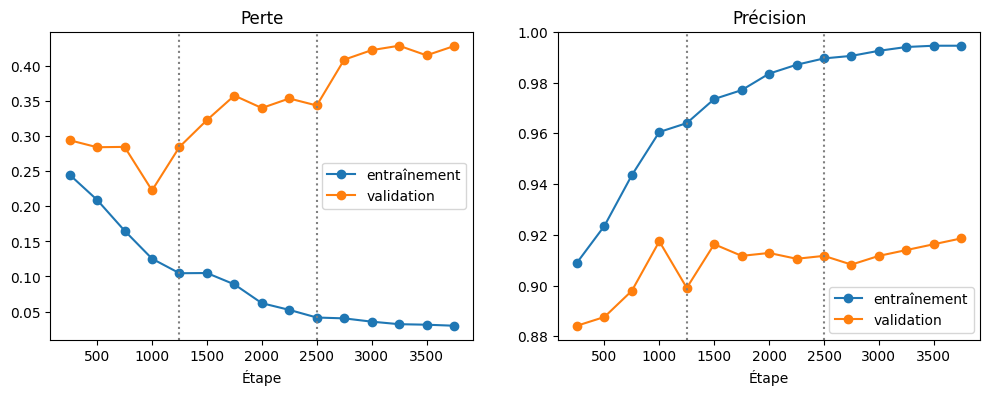

,eval_train_loss,eval_validation_loss,eval_train_accuracy,eval_validation_accuracy
step,,,,
250,0.2451,0.2944,0.9090,0.8842
500,0.2092,0.2844,0.9235,0.8876
750,0.1653,0.2849,0.9435,0.8979
1000,0.1253,0.2228,0.9605,0.9174
1250,0.1046,0.2848,0.9640,0.8991
1500,0.1049,0.3231,0.9735,0.9163
1750,0.0887,0.3581,0.9770,0.9117
2000,0.0619,0.3403,0.9835,0.9128
2250,0.0523,0.3539,0.9870,0.9106


In [12]:
historique = pd.DataFrame(trainer.state.log_history)
courbe = historique.groupby("step").first()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(courbe["eval_train_loss"].dropna(), "o-", label="entraînement")
ax[0].plot(courbe["eval_validation_loss"].dropna(), "o-", label="validation")
ax[0].set_title("Perte"); ax[0].set_xlabel("Étape"); ax[0].legend()

ax[1].plot(courbe["eval_train_accuracy"].dropna(), "o-", label="entraînement")
ax[1].plot(courbe["eval_validation_accuracy"].dropna(), "o-", label="validation")
ax[1].set_title("Précision"); ax[1].set_xlabel("Étape"); ax[1].legend()

for a in ax:
    for fin_epoque in [1250, 2500]:
        a.axvline(fin_epoque, color="gray", linestyle=":")
plt.show()

colonnes_vues = ["eval_train_loss", "eval_validation_loss", "eval_train_accuracy", "eval_validation_accuracy"]
courbe[colonnes_vues].dropna().round(4)

## 5. Évaluer les performances

### Précision et F1 sur la validation

In [13]:
resultats = trainer.predict(validation)
y_vrai = resultats.label_ids
y_pred = np.argmax(resultats.predictions, axis=1)

print(f"Précision : {accuracy_score(y_vrai, y_pred):.2%}")
print(f"Score F1  : {f1_score(y_vrai, y_pred):.4f}")

Précision : 91.86%
Score F1  : 0.9192


### Matrice de confusion

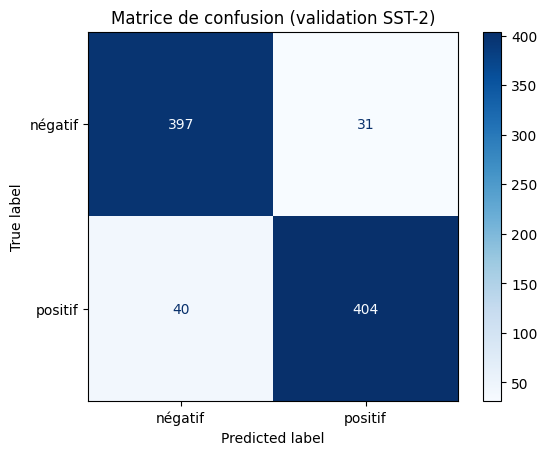

Faux positifs (négatif prédit positif) : 31
Faux négatifs (positif prédit négatif) : 40


In [14]:
cm = confusion_matrix(y_vrai, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["négatif", "positif"]).plot(cmap="Blues")
plt.title("Matrice de confusion (validation SST-2)")
plt.show()

print(f"Faux positifs (négatif prédit positif) : {cm[0, 1]}")
print(f"Faux négatifs (positif prédit négatif) : {cm[1, 0]}")

### Tester avec mes propres phrases

`bert-base-uncased` a été pré-entraîné sur de l'anglais et SST-2 est en anglais, donc les phrases de test doivent être en anglais.

In [16]:
def predire(phrase):
    entree = tokenizer(phrase, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(model.device)
    model.eval()
    with torch.no_grad():
        logits = model(**entree).logits
    proba = torch.softmax(logits, dim=1)[0]
    classe = int(proba.argmax())
    return model.config.id2label[classe], float(proba[classe])

mes_phrases = [
    "I really loved this movie.",
    "The movie was boring.",
    "The movie wasn't bad at all.",
    "Great movie with lots of suspense.",
    "The visual effects were breathtaking.",
]

for phrase in mes_phrases:
    etiquette, confiance = predire(phrase)
    print(f"{etiquette:<8} ({confiance:.1%})  {phrase}")

positif  (100.0%)  I really loved this movie.
négatif  (99.9%)  The movie was boring.
positif  (99.9%)  The movie wasn't bad at all.
positif  (100.0%)  Great movie with lots of suspense.
positif  (100.0%)  The visual effects were breathtaking.


## 6. Réflexion
BERT a très bien performé sur SST-2 : 91,86 % de précision et un score F1 de 0,919 sur les 872 phrases de validation, avec des erreurs bien réparties (31 faux positifs, 40 faux négatifs), alors que je n’ai utilisé que 20 000 phrases d’entraînement sur 67 000. Le fine-tuning a été efficace dès la première époque, où la précision de validation atteint déjà 91,7 % à l’étape 1 000. En revanche, il n’a pas été stable jusqu’au bout : à partir de ce point, la perte de validation passe de 0,22 à 0,43 pendant que la précision d’entraînement monte à 99,5 %, signe que le modèle surapprend et devient trop confiant dans ses erreur. Pour améliorer les résultats, je m’arrêterais après une époque ou j’utiliserais load_best_model_at_end=True pour garder le modèle de l’étape 1 000. J’entraînerais aussi sur les 67 000 phrases du jeu complet, et je pourrais essayer un modèle plus grand comme bert-large ou RoBERTa.